# evm-cluster-check: week-1 result

Everything here is read from `results/`, produced by `make run`. Re-run `make notebook` after a new run.

In [1]:
import os, json
import pandas as pd
from IPython.display import Image, display
os.chdir('..')  # run from the repository root
pd.set_option('display.width', 200)

## The window

In [2]:
json.load(open('results/stats_eth.json'))

{'chain': 'eth',
 'blocks': [26316189, 26337722],
 'transactions': 5440040,
 'logs': 9615381,
 'transfers': 11160360,
 'eth_transfers': 1816424,
 'erc20_transfers': 9343936,
 'userops': 94438,
 'fresh_eoas_funded_in_window': 297360,
 'hubs': 366,
 'por_labels': 452,
 'por_labels_active': 85,
 'ofac_eth_addresses': 127,
 'ofac_active': 0,
 'sweeper_collectors': 362,
 'sweeper_collectors_active': 30,
 'infra_lookalike_pairs': 1321810,
 'infra_sweeper_contracts': 508,
 'infra_sweeper_victims': 5786,
 'infra_delegations_in_window': 71702,
 'infra_bundlers': 194,
 'infra_paymasters': 47,
 'flagged_poison_zero': 516787,
 'flagged_poison_lookalike': 2111714,
 'flagged_sweeper': 1115,
 'flagged_aa_infra': 27803,
 'flagged_infra_any': 2327606}

## False merges by rule (full labels, hubs included and excluded)

In [3]:
r = pd.read_csv('results/rules_eth.csv')
cols = ['hubs','rule','clustered_addresses','labelled_linked','cross_exchange_pairs_linked','clusters_with_2plus_exchanges','pair_precision','pw_precision','aer']
r[r.protocol=='full'][cols]

,hubs,rule,clustered_addresses,labelled_linked,cross_exchange_pairs_linked,clusters_with_2plus_exchanges,pair_precision,pw_precision,aer
0,included,dar_naive,10892,36,198,1,0.544828,0.000843,0.483954
1,included,dar_victor,8848,0,0,0,NaN,0.000000,0.557324
2,included,dar_hubfiltered,9668,0,0,0,NaN,0.000000,0.557324
3,included,funder_naive,345209,10,0,0,NaN,0.000000,0.557324
4,included,funder_hubfiltered,144375,2,0,0,NaN,0.000000,0.557324
5,included,funder_aa_sponsor,377790,10,0,0,NaN,0.000000,0.557324
6,included,cospend,226018,36,359,1,0.430159,0.000007,0.434653
7,included,all,542190,40,449,1,0.424359,0.000004,0.418349
48,excluded,dar_naive,1026,11,0,0,NaN,0.000000,0.516508
49,excluded,dar_victor,930,0,0,0,NaN,0.000000,0.516508


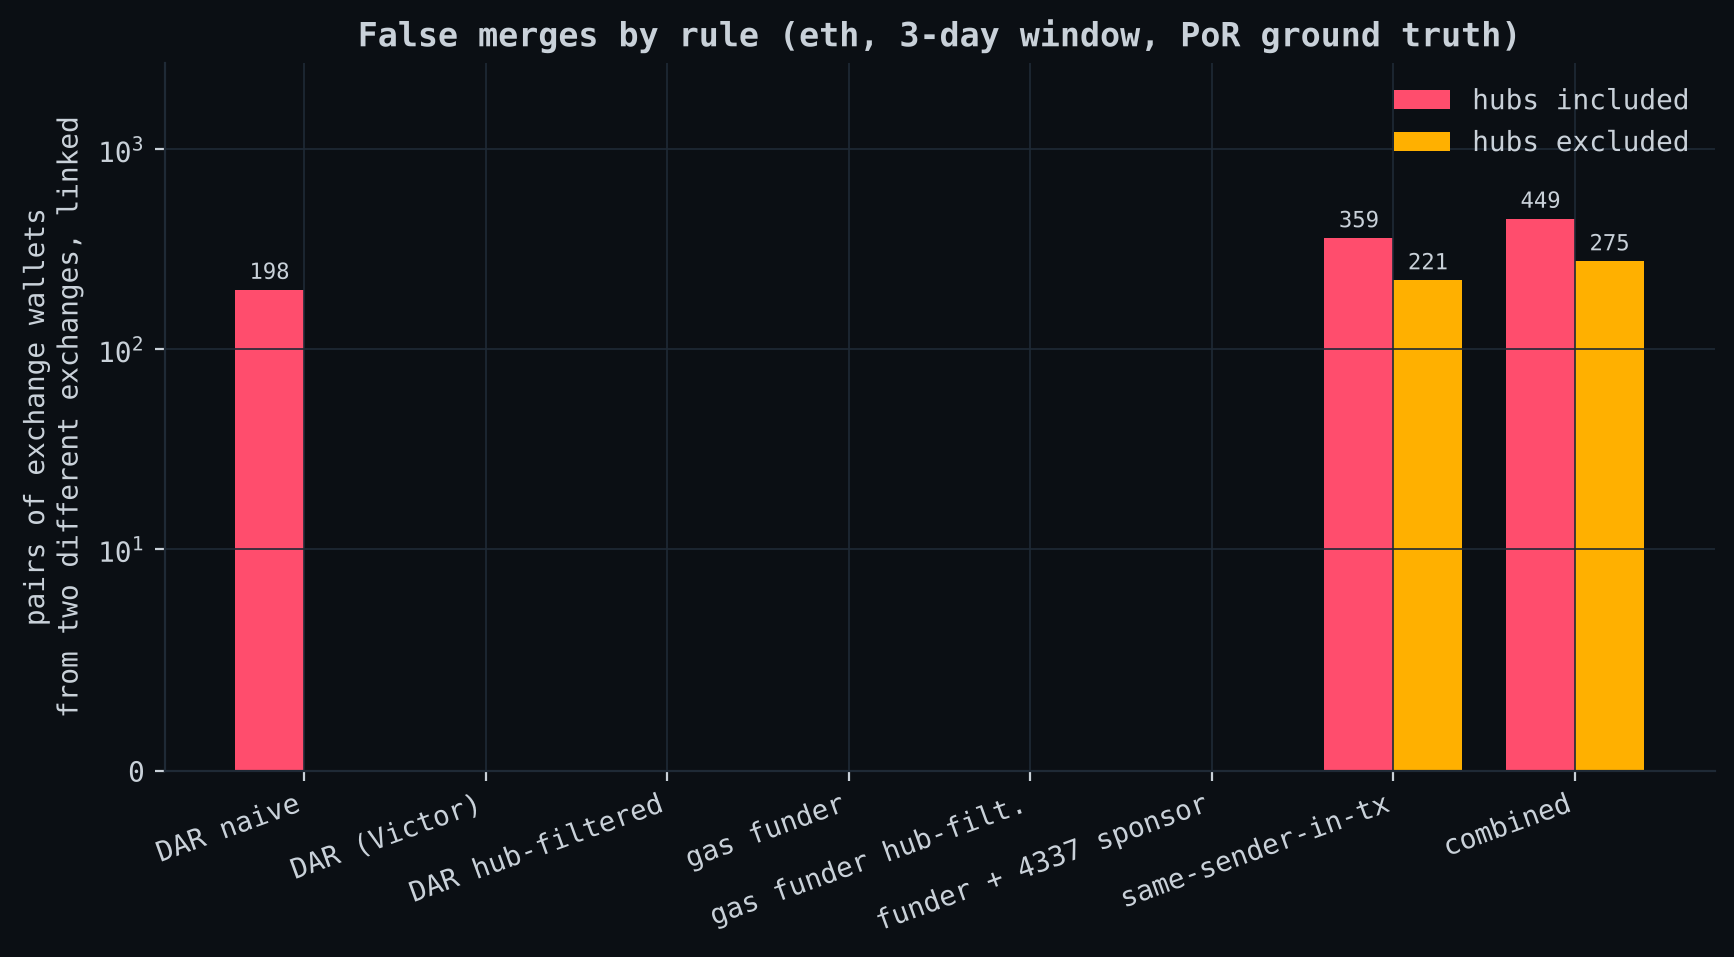

In [4]:
display(Image('docs/img/false_merges_by_rule_eth.png'))

## Incomplete labels: the 50/50 split protocol (mean over splits)

In [5]:
s = r[r.protocol=='split50'].groupby(['hubs','rule'])[['cross_exchange_pairs_linked','clusters_with_2plus_exchanges','pair_precision','pw_precision']].agg(['mean','min','max'])
s

cross_exchange_pairs_linked          clusters_with_2plus_exchanges         pair_precision                     pw_precision                    
                                                mean min  max                          mean min max           mean       min       max         mean       min       max
hubs     rule                                                                                                                                                          
excluded all                                    71.3  27  104                           1.0   1   1       0.420496  0.266667  0.615385     0.000003  0.000002  0.000005
         dar_hubfiltered                         0.0   0    0                           0.0   0   0            NaN       NaN       NaN     0.000000  0.000000  0.000000
         dar_naive                               0.0   0    0                           0.0   0   0            NaN       NaN       NaN     0.000000  0.000000  0.000000
         dar_victor                              0.0   0    0                           0.0   0   0            NaN       NaN       NaN     0.000000  0.000000  0.000000
included all                                   134.9  63  204                           1.0   1   1       0.461394  0.362319  0.631579     0.000004  0.000002  0.000005
         dar_hubfiltered                         3.2   0    8                           0.7   0   1       0.231293  0.000000  0.500000     0.003517  0.000000  0.022902
         dar_naive                              23.7   5   49                           1.0   1   1       0.385497  0.142857  0.666667     0.000330  0.000015  0.000821
         dar_victor                             17.2   0   49                           0.8   0   1       0.288942  0.000000  0.461538     0.000255  0.000000  0.000742

## What causes them

In [6]:
pd.read_csv('results/infra_eth.csv')

,rule,false_pairs,false_pairs_without_poisoning,share_caused_by_poisoning,false_pairs_without_sweeper,share_caused_by_sweeper,false_pairs_without_aa_bundler_paymaster,share_caused_by_aa_bundler_paymaster,false_pairs_without_all_infrastructure,share_caused_by_all_infrastructure
0,dar_naive,198,198,0.000000,198,0.0,198,0.0,198,0.000000
1,dar_victor,0,0,NaN,0,NaN,0,NaN,0,NaN
2,dar_hubfiltered,0,0,NaN,0,NaN,0,NaN,0,NaN
3,funder_naive,0,0,NaN,0,NaN,0,NaN,0,NaN
4,funder_hubfiltered,0,0,NaN,0,NaN,0,NaN,0,NaN
5,funder_aa_sponsor,0,0,NaN,0,NaN,0,NaN,0,NaN
6,cospend,359,143,0.601671,359,0.0,359,0.0,143,0.601671
7,all,449,218,0.514477,449,0.0,449,0.0,218,0.514477


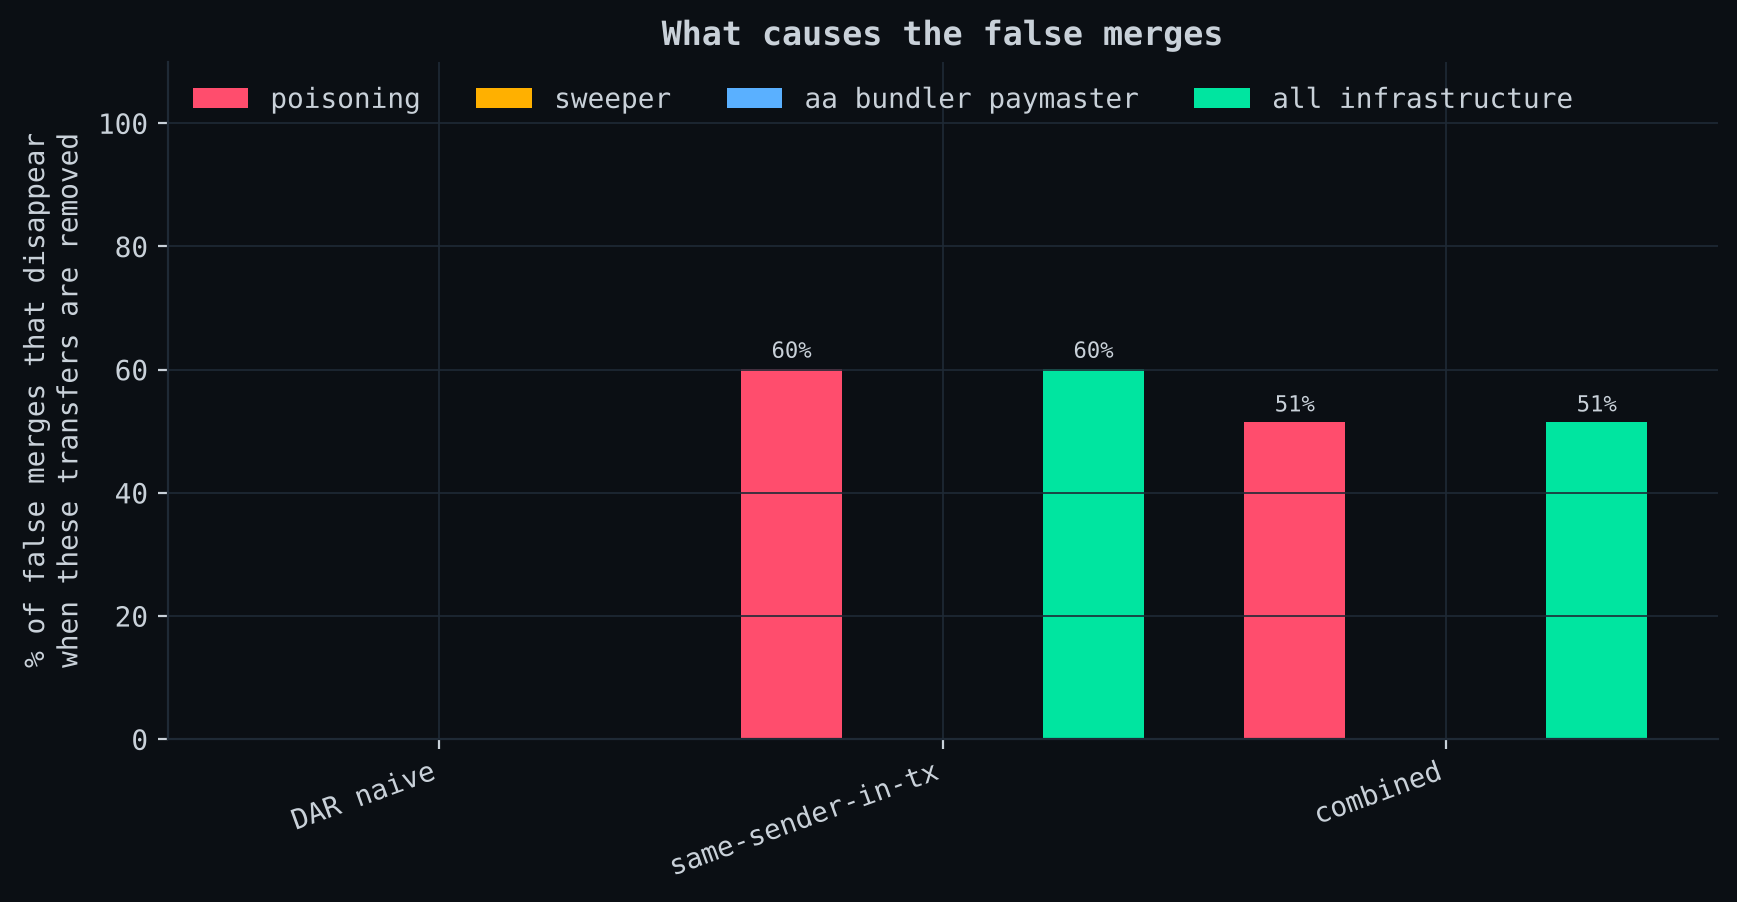

In [7]:
display(Image('docs/img/infra_causes_eth.png'))

## Uncertainty

In [8]:
b = pd.read_csv('results/bootstrap_eth.csv'); b.cross_exchange_pairs_linked.describe(percentiles=[.025,.5,.975])

count    300.000000
mean     200.840000
std       84.693749
min       82.000000
2.5%      97.950000
50%      165.000000
97.5%    359.000000
max      359.000000
Name: cross_exchange_pairs_linked, dtype: float64

In [9]:
pd.read_csv('results/per_day_eth.csv')[['day','rule','cross_exchange_pairs_linked','pair_precision']]

,day,rule,cross_exchange_pairs_linked,pair_precision
0,1,dar_naive,99,0.608696
1,2,dar_naive,63,0.631579
2,3,dar_naive,84,0.557895
3,1,dar_victor,0,NaN
4,2,dar_victor,0,NaN
5,3,dar_victor,0,NaN
6,1,all,389,0.415916
7,2,all,332,0.473016
8,3,all,106,0.307190


## Taint

In [10]:
pd.read_csv('results/taint_eth.csv')

,edges,hops,tainted_addresses,exchange_por_wallets_tainted,exchanges_reached,seeds
0,all_transfers,1,0,0,0,ofac_sdn
1,all_transfers,2,0,0,0,ofac_sdn
2,all_transfers,3,0,0,0,ofac_sdn
3,no_zero_value,1,0,0,0,ofac_sdn
4,no_zero_value,2,0,0,0,ofac_sdn
5,no_zero_value,3,0,0,0,ofac_sdn
6,no_poisoning,1,0,0,0,ofac_sdn
7,no_poisoning,2,0,0,0,ofac_sdn
8,no_poisoning,3,0,0,0,ofac_sdn
9,no_infrastructure,1,0,0,0,ofac_sdn


In [11]:
json.load(open('results/haircut_eth.json'))

{'ofac_sdn': {'haircut_addresses_any_share': 0,
  'haircut_addresses_share_ge_1pct': 0,
  'haircut_addresses_share_ge_50pct': 0,
  'haircut_por_wallets_any_share': 0},
 'sweeperhunter_collectors': {'haircut_addresses_any_share': 205090,
  'haircut_addresses_share_ge_1pct': 5966,
  'haircut_addresses_share_ge_50pct': 2418,
  'haircut_por_wallets_any_share': 22}}

## Hand-checked false merges

In [12]:
pd.read_csv('results/handcheck_eth.csv')[['case','exchange_a','exchange_b','hops','link_kinds','cause']]

,case,exchange_a,exchange_b,hops,link_kinds,cause
0,1,Bitfinex,Gemini,2,cospend > cospend,unexplained by these rules
1,2,OKX,KuCoin,3,dar > cospend > cospend,exchange wallet paid a deposit address (treate...
2,3,OKX,Bitrue,5,dar > dar > dar > dar > cospend,chain passes through a third exchange's wallet...
3,4,OKX,KuCoin,3,cospend > cospend > cospend,poisoning transfers in one transaction
4,5,OKX,KuCoin,5,cospend > cospend > cospend > dar > dar,exchange wallet paid a deposit address (treate...
5,6,OKX,Bitget,3,cospend > cospend > cospend,unlabelled high-degree hub on the chain
6,7,OKX,Gate,4,cospend > cospend > cospend > cospend,poisoning transfers in one transaction
7,8,OKX,Bitget,4,dar > dar > cospend > cospend,exchange wallet paid a deposit address (treate...
8,9,OKX,Gate,5,dar > cospend > cospend > cospend > cospend,exchange wallet paid a deposit address (treate...
9,10,KuCoin,Gate,4,cospend > cospend > cospend > cospend,poisoning transfers in one transaction


## Reproduction against Victor (2020) and Tutela (2022)

In [13]:
json.load(open('results/reproduce_eth.json'))

{'window_blocks': [26316189, 26337722],
 'eth_eoa_forward_paths_loose': 5537,
 'amax_p95_eth': 0.4628106192262894,
 'tmax_p95_blocks': 4828.599999999993,
 'deposit_addresses': 26762,
 'deposit_users': 9946,
 'share_users_sharing_deposit': 0.2417052081238689,
 'multi_address_clusters': 444,
 'mean_cluster_size_multi': 2.9481981981981984,
 'sd_cluster_size_multi': 6.418407599562969,
 'largest_cluster': 102,
 'victor_2020': {'amax_p95_eth': 0.0083,
  'tmax_p95_blocks': 3185,
  'share_users_sharing_deposit': 0.443},
 'tutela_2022': {'mean_cluster_size': 4.3,
  'sd_cluster_size': 8.6,
  'largest_cluster': 2100}}

## Injected ground truth (synthetic, local fork)

In [14]:
pd.read_csv('results/injected.csv')

,rule,edges,true_links,false_links,false_link_owner_pairs
0,dar_naive,all,1,3,carol~bob; exchange-2~alice
1,dar_naive,infra_removed,1,3,carol~bob; exchange-2~alice
2,dar_victor,all,1,1,carol~bob
3,dar_victor,infra_removed,1,1,carol~bob
4,dar_hubfiltered,all,1,1,carol~bob
5,dar_hubfiltered,infra_removed,1,1,carol~bob
6,funder_naive,all,0,3,alice~carol; exchange-1~alice; exchange-1~carol
7,funder_naive,infra_removed,0,3,alice~carol; exchange-1~alice; exchange-1~carol
8,funder_hubfiltered,all,0,3,alice~carol; exchange-1~alice; exchange-1~carol
9,funder_hubfiltered,infra_removed,0,3,alice~carol; exchange-1~alice; exchange-1~carol
